# Una IA contra 353 problemas abiertos de Erdős

**353 problemas de Erdős sin resolver. Un agente de inteligencia artificial los intentó todos y cerró 9. ¿Es mucho o es poco?** Depende de con qué lo compares.

**Paper:** Tsoukalas et al. (2026). *Advancing mathematics research with AI-driven formal proof search*. **Science**.
**DOI:** [10.1126/science.aej2213](https://doi.org/10.1126/science.aej2213)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ciencia-a-Mordiscos/lab/blob/main/papers/2026-10-08-ia-busqueda-pruebas-formales-erdos/notebook.ipynb)

**Video:** Pendiente

Paul Erdős, un matemático húngaro del siglo XX, dejó cientos de preguntas matemáticas abiertas; el sitio *Erdős Problems* cataloga más de 1.200. Los modelos de lenguaje (LLM) ya resuelven muchos ejercicios de matemáticas, pero se equivocan con total aplomo, y eso los vuelve poco útiles para investigar. La salida que eligió este equipo: obligar a la IA a escribir cada prueba en **Lean**, un lenguaje de programación donde el compilador revisa cada paso. Si el archivo compila, la prueba es válida para el enunciado formal; si no, no hay discusión.

Construyeron un agente, **AlphaProof Nexus**, que alterna un LLM (Gemini 3.1 Pro) con AlphaProof (otro sistema que busca pruebas en Lean por su cuenta, al que el agente le consulta pasos intermedios) y el verificador de Lean. Los autores dicen que es la primera vez que se muestra que este método sirve para resolver problemas abiertos a gran escala.

Lo que podemos abrir: los **71 archivos Lean** que publicaron en Zenodo (69 pruebas completas y 2 con huecos marcados con `sorry`), la lista de los **353 problemas de Erdős** y las **492 conjeturas de la OEIS** (la enciclopedia en línea de sucesiones de enteros) que el agente intentó, y la comparación con otros sistemas que cuenta el material suplementario. Lo que no podemos reproducir: el costo en dólares, que solo aparece en figuras sin números.

In [1]:
# ══════════════════════════════════════════════════════════════
# Configuración — modifica estos valores para explorar
# ══════════════════════════════════════════════════════════════
DOMINIO_HIST = 'OEIS'               # distribución del histograma final: 'OEIS', 'StacksProject', 'AICollaborator', 'ErdosProblems'
DOMINIO_REF = 'ErdosProblems'       # dominio cuya mediana se marca encima
TACTICA = 'omega'                   # táctica de Lean para la celda experimental (ej: 'have', 'simp', 'nlinarith')
OEIS_RESUELTOS_PAPER = 44           # lo que reporta el paper (abstract); el repo público trae menos archivos
FUENTE = 'Fuente: Tsoukalas et al. (2026), Science | Datos: Zenodo, doi:10.5281/zenodo.21477349'
COLOR_DATOS = '#2563EB'
COLOR_ALERTA = '#DC2626'
COLOR_REFERENCIA = '#D97706'
COLOR_SECUNDARIO = '#059669'
COLOR_VIOLETA = '#7C3AED'
COLOR_CONTEXTO = '#BBBBBB'

import os, re, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats

BASE = 'https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/papers/2026-10-08-ia-busqueda-pruebas-formales-erdos'
ARCHIVOS = ['pruebas_lean.csv', 'tacticas_por_prueba.csv',
            'problemas_intentados.csv', 'comparacion_sistemas_erdos.csv']
os.makedirs('datos', exist_ok=True)
os.makedirs('figuras', exist_ok=True)
for a in ARCHIVOS:
    if not os.path.exists(f'datos/{a}'):
        urllib.request.urlretrieve(f'{BASE}/datos/{a}', f'datos/{a}')

style_file = '../../cam.mplstyle'
if not os.path.exists(style_file):
    style_file = '/tmp/cam.mplstyle'
    if not os.path.exists(style_file):
        urllib.request.urlretrieve('https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main/cam.mplstyle', style_file)
plt.style.use(style_file)

# Números en formato español: coma decimal, punto de miles
def es(x):
    s = str(x)
    s = re.sub(r'(?<=\d)\.(?=\d)', ',', s)
    return s

def mil(n):
    return f'{n:,}'.replace(',', '.')

def pr(*a):
    print(*[es(x) for x in a])

COMA = FuncFormatter(lambda v, _: es(f'{v:g}'))

NOMBRE = {'ErdosProblems': 'Erdős', 'OEIS': 'OEIS',
          'StacksProject': 'Stacks Project', 'AICollaborator': 'Colaboraciones'}
COLOR_DOM = {'ErdosProblems': COLOR_ALERTA, 'OEIS': COLOR_DATOS,
             'StacksProject': COLOR_SECUNDARIO, 'AICollaborator': COLOR_VIOLETA}

# 1 fila por archivo .lean publicado. lineas_codigo = líneas no vacías sin comentarios ni
# encabezados (import/open/namespace...): incluye enunciado, definiciones, lemas y prueba.
# Es una medida de tamaño del archivo, no de "pasos de razonamiento".
pruebas = pd.read_csv('datos/pruebas_lean.csv')
completas = pruebas[pruebas['prueba_completa']].copy()   # sin 'sorry' (huecos sin probar)
tacticas = pd.read_csv('datos/tacticas_por_prueba.csv')  # conteo léxico de 30 tácticas por archivo
problemas = pd.read_csv('datos/problemas_intentados.csv')
sistemas = pd.read_csv('datos/comparacion_sistemas_erdos.csv')  # transcrito del material suplementario

n_erdos = (problemas['benchmark'] == 'Erdos').sum()
n_oeis = (problemas['benchmark'] == 'OEIS').sum()
erdos = completas[completas['dominio'] == 'ErdosProblems']
oeis = completas[completas['dominio'] == 'OEIS']

pr(f'Archivos Lean publicados: {len(pruebas)} ({len(completas)} completos, {len(pruebas) - len(completas)} parciales con sorry)')
for dom, n in pruebas['dominio'].value_counts().items():
    pr(f'  {NOMBRE[dom]:<15} {n} archivos')
n_numeros_erdos = problemas.loc[problemas['benchmark'] == 'Erdos', 'numero'].nunique()
pr(f'Problemas intentados: Erdős {n_erdos} ({n_numeros_erdos} números de problema distintos) | OEIS {n_oeis}')
pr(f'Erdős resueltos (archivos): {len(erdos)} de {n_erdos} = {100 * len(erdos) / n_erdos:.2f} %')
pr(f'OEIS: {OEIS_RESUELTOS_PAPER} de {n_oeis} según el paper = {100 * OEIS_RESUELTOS_PAPER / n_oeis:.2f} % | '
   f'{len(oeis)} con prueba en el repo = {100 * len(oeis) / n_oeis:.2f} %')
pr(f'Respuesta formal en los 9 de Erdős: {(erdos["answer"] == True).sum()} «sí» (True), {(erdos["answer"] == False).sum()} «no» (False)')

Archivos Lean publicados: 71 (69 completos, 2 parciales con sorry)
  OEIS            38 archivos
  Colaboraciones  13 archivos
  Stacks Project  11 archivos
  Erdős           9 archivos
Problemas intentados: Erdős 353 (237 números de problema distintos) | OEIS 492
Erdős resueltos (archivos): 9 de 353 = 2,55 %
OEIS: 44 de 492 según el paper = 8,94 % | 38 con prueba en el repo = 7,72 %
Respuesta formal en los 9 de Erdős: 4 «sí» (True), 5 «no» (False)


Aquí está.

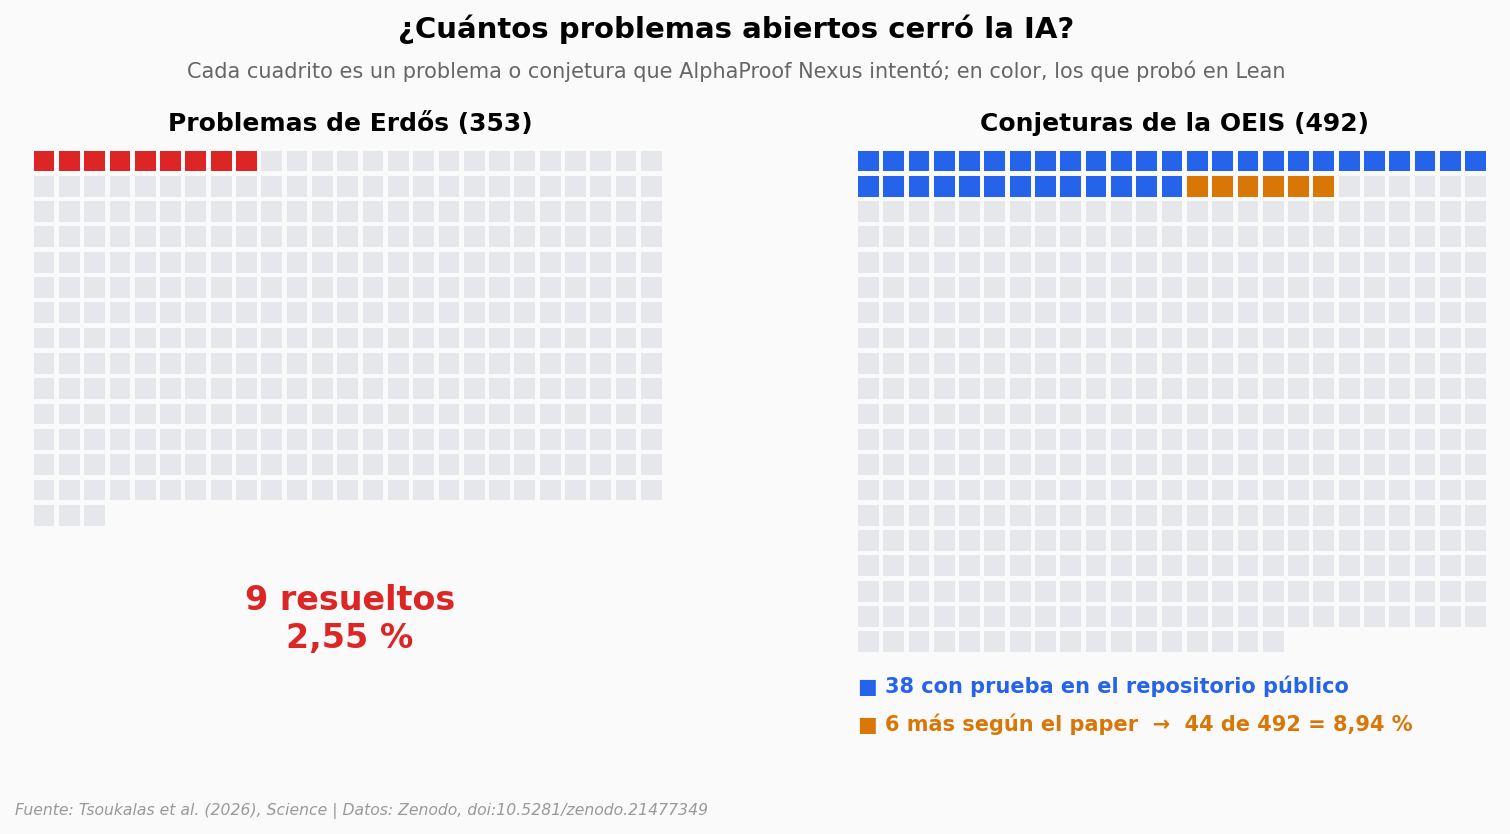

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
COLS = 25
FILAS_MAX = int(np.ceil(max(n_erdos, n_oeis) / COLS))

def waffle(ax, total, grupos):
    colores = []
    for n, c in grupos:
        colores += [c] * n
    colores += ['#E5E7EB'] * (total - len(colores))
    for i, c in enumerate(colores):
        fila, col = divmod(i, COLS)
        ax.add_patch(plt.Rectangle((col, FILAS_MAX - 1 - fila), 0.82, 0.82, color=c, lw=0))
    ax.set_xlim(-0.3, COLS + 0.2)
    ax.set_ylim(-3.5, FILAS_MAX + 1.6)
    ax.set_aspect('equal')
    ax.axis('off')

n_oeis_repo = len(oeis)
waffle(axes[0], n_erdos, [(len(erdos), COLOR_ALERTA)])
waffle(axes[1], n_oeis, [(n_oeis_repo, COLOR_DATOS),
                         (OEIS_RESUELTOS_PAPER - n_oeis_repo, COLOR_REFERENCIA)])

axes[0].text(COLS / 2, FILAS_MAX + 0.6, f'Problemas de Erdős ({n_erdos})',
             ha='center', fontsize=12, fontweight='bold')
axes[1].text(COLS / 2, FILAS_MAX + 0.6, f'Conjeturas de la OEIS ({n_oeis})',
             ha='center', fontsize=12, fontweight='bold')

filas_erdos = int(np.ceil(n_erdos / COLS))
axes[0].text(COLS / 2, (FILAS_MAX - filas_erdos) / 2 - 1.2,
             f'{len(erdos)} resueltos\n' + es(f'{100 * len(erdos) / n_erdos:.2f}') + ' %',
             ha='center', va='center', fontsize=16, fontweight='bold', color=COLOR_ALERTA)
axes[1].text(0, -1.6, f'■ {n_oeis_repo} con prueba en el repositorio público',
             fontsize=10, color=COLOR_DATOS, fontweight='bold')
axes[1].text(0, -3.1, f'■ {OEIS_RESUELTOS_PAPER - n_oeis_repo} más según el paper  →  '
             f'{OEIS_RESUELTOS_PAPER} de {n_oeis} = ' + es(f'{100 * OEIS_RESUELTOS_PAPER / n_oeis:.2f}') + ' %',
             fontsize=10, color=COLOR_REFERENCIA, fontweight='bold')

# Los paneles con aspecto fijo no llenan la altura: título y subtítulo van pegados a ellos
fig.suptitle('¿Cuántos problemas abiertos cerró la IA?', fontsize=14, fontweight='bold', y=0.99)
fig.text(0.5, 0.935, 'Cada cuadrito es un problema o conjetura que AlphaProof Nexus intentó; en color, los que probó en Lean',
         fontsize=10, color='#666666', ha='center', va='top')
fig.text(0.13, 0.02, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/hero_problemas_resueltos.png', dpi=200, bbox_inches='tight')
plt.show()

Lo que llama la atención: casi todo el tablero sigue gris. En Erdős, 9 de 353, un 2,55 %. En la OEIS, 44 de 492 según el paper (8,94 %), aunque en el repositorio público solo encontramos 38 pruebas (7,72 %). Con los datos abiertos no podemos saber dónde están las otras 6.

Ojo con el denominador. Los 353 no son todos los problemas de Erdős: son los que la comunidad ya había traducido a Lean en el repositorio Formal Conjectures a inicios de febrero de 2026. Equivalen a 237 números de problema distintos, porque varios vienen partidos en partes o variantes. El propio material suplementario reconoce el sesgo: solo entran los problemas que alguien logró formalizar.

Y no todo fue confirmar conjeturas: en 5 de los 9 problemas de Erdős la respuesta que el agente probó es «no» (`answer(False)`), y en 4 es «sí».

¿Los habría resuelto cualquier IA? El equipo puso a otros sistemas frente a los mismos 9 problemas de Erdős.

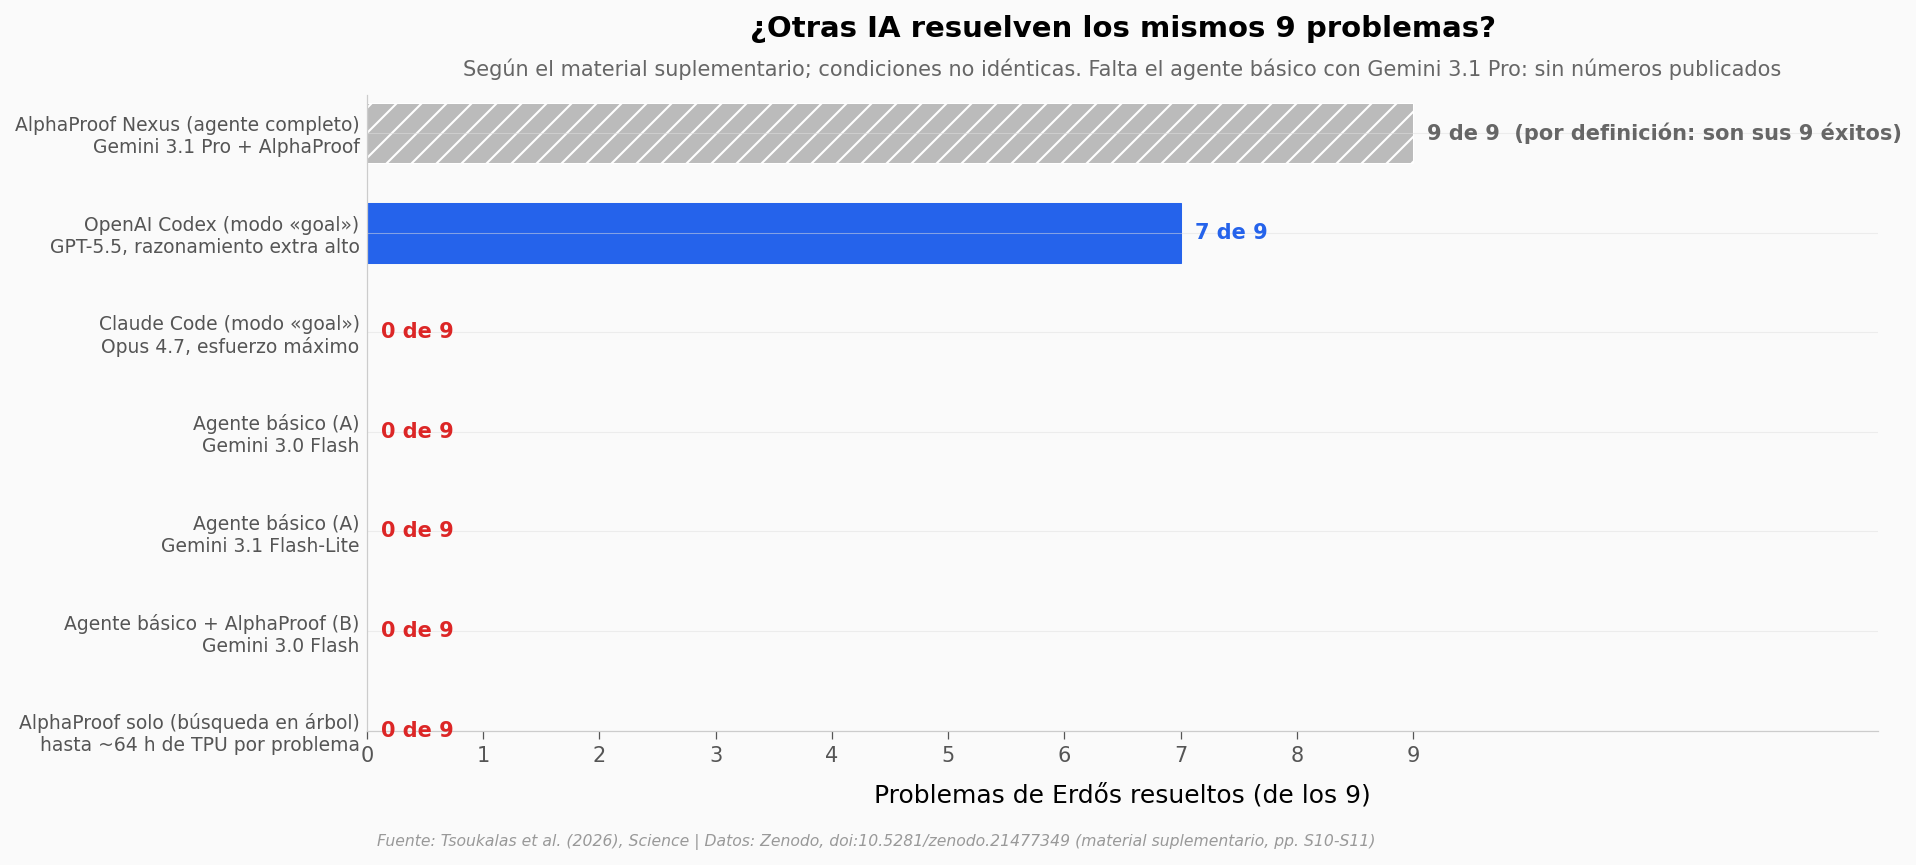

Codex: 7 de 9 | sistemas con 0 de 9: 5 de 6 comparados


In [3]:
SISTEMA_ES = {
    'AlphaProof Nexus (agente completo D)': 'AlphaProof Nexus (agente completo)',
    'OpenAI Codex (goal mode)': 'OpenAI Codex (modo «goal»)',
    'Claude Code (goal mode)': 'Claude Code (modo «goal»)',
    'Agente basico A': 'Agente básico (A)',
    'Agente basico + AlphaProof (B)': 'Agente básico + AlphaProof (B)',
    'AlphaProof solo (tree search, ~64 h TPU v6e/problema)': 'AlphaProof solo (búsqueda en árbol)',
}
MODELO_ES = {'GPT-5.5 extra-high': 'GPT-5.5, razonamiento extra alto',
             'Opus 4.7 max effort': 'Opus 4.7, esfuerzo máximo',
             'AlphaProof': 'hasta ~64 h de TPU por problema'}
s = sistemas.copy()
s['etiqueta'] = [f"{SISTEMA_ES.get(a, a)}\n{MODELO_ES.get(b, b)}" for a, b in zip(s['sistema'], s['modelo'])]
y = np.arange(len(s))
es_nexus = s['sistema'].str.startswith('AlphaProof Nexus')

fig, ax = plt.subplots(figsize=(13, 5.5))
for yi, (_, fila) in zip(y, s.iterrows()):
    nexus = fila['sistema'].startswith('AlphaProof Nexus')
    color = COLOR_CONTEXTO if nexus else (COLOR_DATOS if fila['resueltos'] > 0 else COLOR_ALERTA)
    if fila['resueltos'] > 0:
        ax.barh(yi, fila['resueltos'], color=color, height=0.6,
                hatch='//' if nexus else None, edgecolor='white' if nexus else color)
    texto = f"{fila['resueltos']} de {fila['total']}"
    if nexus:
        texto += '  (por definición: son sus 9 éxitos)'
    ax.text(fila['resueltos'] + 0.12, yi, texto, va='center', fontsize=10, fontweight='bold',
            color='#666666' if nexus else color)
ax.set_yticks(y)
ax.set_yticklabels(s['etiqueta'], fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 13)
ax.set_xticks(range(0, 10))
ax.set_xlabel('Problemas de Erdős resueltos (de los 9)')
ax.set_title('¿Otras IA resuelven los mismos 9 problemas?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Según el material suplementario; condiciones no idénticas. Falta el agente básico con Gemini 3.1 Pro: sin números publicados',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE + ' (material suplementario, pp. S10-S11)', fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/comparacion_sistemas.png', dpi=200, bbox_inches='tight')
plt.show()

codex = s.loc[s['sistema'].str.contains('Codex'), 'resueltos'].iloc[0]
pr(f'Codex: {codex} de 9 | sistemas con 0 de 9: {(s["resueltos"] == 0).sum()} de {len(s) - 1} comparados')

Codex (GPT-5.5) es el único que se acerca: 7 de 9. Resolvió seis al primer intento y el #12-(ii) al segundo; el #152 y el #125 se le resistieron tras dos intentos y 12 horas. Claude Code (Opus 4.7) se quedó en 0, incluso después de que el equipo le cambiara el prompt: en la primera corrida se negó a intentarlo porque era un problema abierto. Los agentes básicos con modelos Gemini Flash, 0. AlphaProof por sí solo, con un presupuesto de unas 64 horas de TPU (los chips de IA de Google) por problema, también 0.

Esto no es un experimento controlado: cada sistema tuvo un número distinto de intentos y de horas, y para Codex no hay cifras de costo. Además, el abstract dice que incluso un agente básico, que solo alterna el LLM con el verificador de Lean, replicó los éxitos en Erdős. Según el material suplementario, ese agente usa Gemini 3.1 Pro; su resultado vive en figuras sin números y no lo podemos verificar aquí.

¿Cómo son esas pruebas por dentro? En cada archivo medimos dos cosas: **líneas de código** (sin comentarios ni encabezados; incluye el enunciado, las definiciones, los lemas y la prueba) y **declaraciones auxiliares**: todo lo que el archivo declara además del teorema principal. La mayoría son lemas, los resultados intermedios demostrados por el camino, pero también cuentan las definiciones: un 24 % del total.

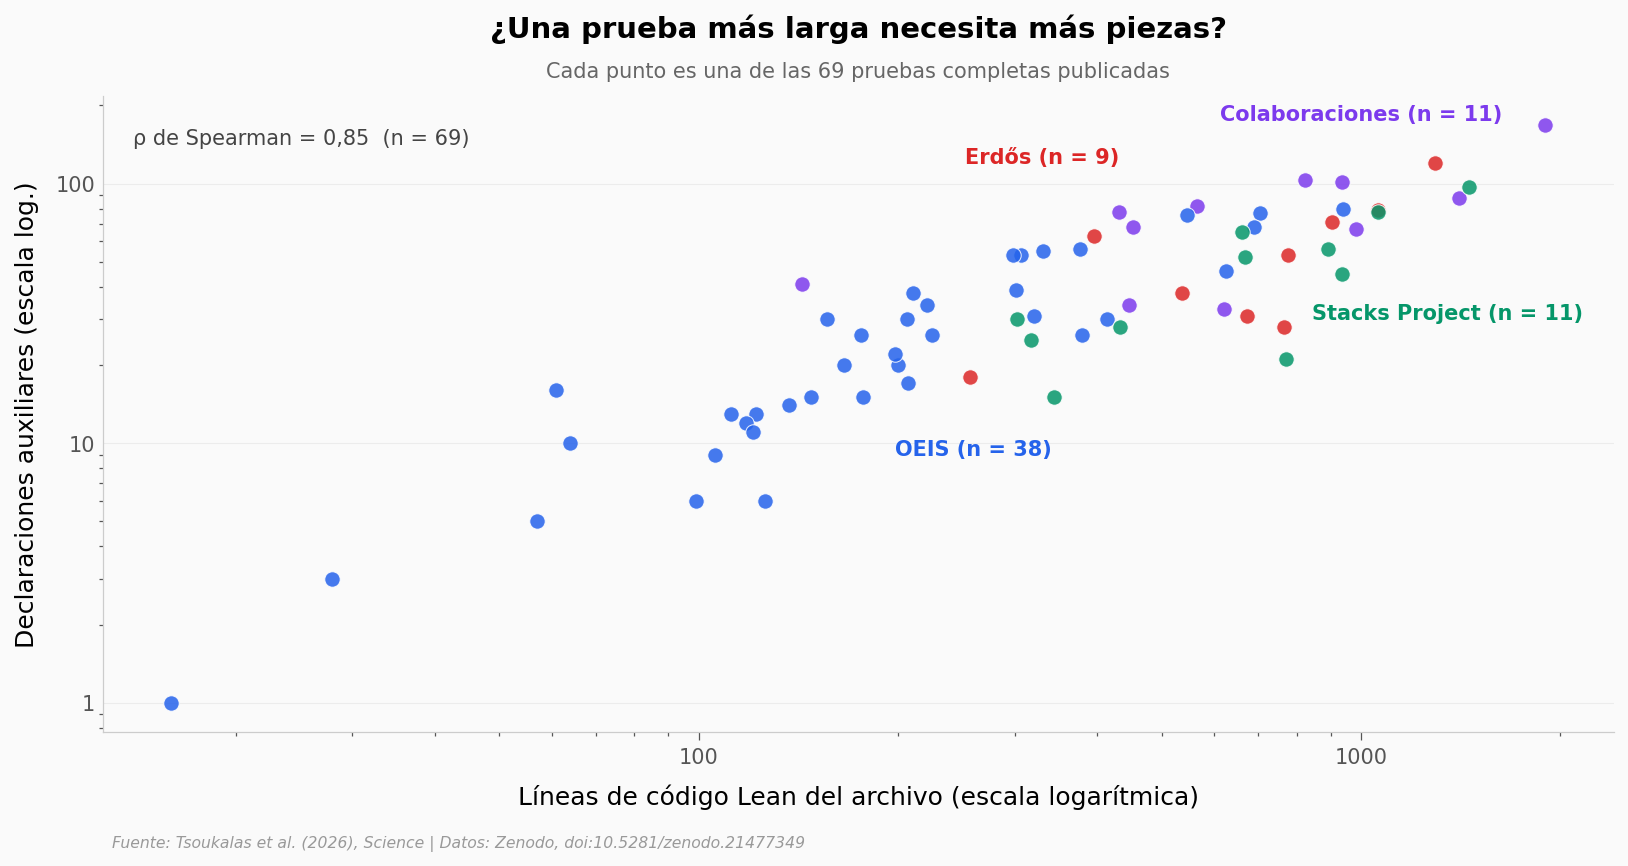

                 n  lineas_mediana  lineas_p25  lineas_p75  decl_aux_mediana  defs_mediana
Erdős            9             764         536         904                53            12
Stacks Project  11             669         388         914                45             5
Colaboraciones  11             620         450         959                78            34
OEIS            38             199         121         318                24             5
Spearman ρ = 0,85, p = 2,2e-20
Máximo de declaraciones auxiliares en Erdős: 120 (erdos_741.parts.i.lean)
Parte de las declaraciones auxiliares que son definiciones: 24 %
Declaraciones auxiliares, Colaboraciones vs Erdős: Mann-Whitney p = 0,13, rank-biserial = 0,41 (n = 11 vs 9)
Líneas, Erdős vs Stacks Project: Mann-Whitney p = 0,76
Líneas, Erdős vs Colaboraciones: Mann-Whitney p = 1,00


In [4]:
# Etiquetas en zonas vacías del gráfico (líneas, lemas)
POS_ETIQUETA = {'OEIS': (260, 9), 'ErdosProblems': (330, 120),
                'StacksProject': (1350, 30), 'AICollaborator': (1000, 175)}
fig, ax = plt.subplots(figsize=(13, 5.5))
for dom, g in completas.groupby('dominio'):
    ax.scatter(g['lineas_codigo'], g['n_lemas_auxiliares'], color=COLOR_DOM[dom], s=55, alpha=0.85,
               edgecolors='white', linewidths=0.5, zorder=5)
    lx, ly = POS_ETIQUETA[dom]
    ax.text(lx, ly, f'{NOMBRE[dom]} (n = {len(g)})',
            color=COLOR_DOM[dom], fontsize=10, fontweight='bold', ha='center', zorder=6)
ax.set_xscale('log')
ax.set_yscale('log')
ax.xaxis.set_major_formatter(COMA)
ax.yaxis.set_major_formatter(COMA)
ax.set_xlabel('Líneas de código Lean del archivo (escala logarítmica)')
ax.set_ylabel('Declaraciones auxiliares (escala log.)')

rho, p_rho = stats.spearmanr(completas['lineas_codigo'], completas['n_lemas_auxiliares'])
ax.text(0.02, 0.95, f'ρ de Spearman = {es(f"{rho:.2f}")}  (n = {len(completas)})',
        transform=ax.transAxes, fontsize=10, color='#444444', va='top')
ax.set_title('¿Una prueba más larga necesita más piezas?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Cada punto es una de las 69 pruebas completas publicadas',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/lineas_vs_lemas.png', dpi=200, bbox_inches='tight')
plt.show()

resumen = completas.groupby('dominio').agg(
    n=('archivo', 'size'),
    lineas_mediana=('lineas_codigo', 'median'),
    lineas_p25=('lineas_codigo', lambda v: v.quantile(0.25)),
    lineas_p75=('lineas_codigo', lambda v: v.quantile(0.75)),
    decl_aux_mediana=('n_lemas_auxiliares', 'median'),
    defs_mediana=('n_def', 'median'),
).sort_values('lineas_mediana', ascending=False)
resumen.index = [NOMBRE[d] for d in resumen.index]
print(resumen.round(0).astype(int).to_string())
pr(f'Spearman ρ = {rho:.2f}, p = {p_rho:.1e}')
top = erdos.loc[erdos['n_lemas_auxiliares'].idxmax()]
pr(f"Máximo de declaraciones auxiliares en Erdős: {top['n_lemas_auxiliares']} ({top['archivo']})")
pr(f"Parte de las declaraciones auxiliares que son definiciones: {100 * completas['n_def'].sum() / completas['n_lemas_auxiliares'].sum():.0f} %")
colab = completas[completas['dominio'] == 'AICollaborator']
u_c = stats.mannwhitneyu(colab['n_lemas_auxiliares'], erdos['n_lemas_auxiliares'], alternative='two-sided')
pr(f"Declaraciones auxiliares, Colaboraciones vs Erdős: Mann-Whitney p = {u_c.pvalue:.2f}, "
   f"rank-biserial = {2 * u_c.statistic / (len(colab) * len(erdos)) - 1:.2f} (n = {len(colab)} vs {len(erdos)})")
for dom in ['StacksProject', 'AICollaborator']:
    g = completas[completas['dominio'] == dom]
    pr(f"Líneas, Erdős vs {NOMBRE[dom]}: Mann-Whitney p = {stats.mannwhitneyu(erdos['lineas_codigo'], g['lineas_codigo']).pvalue:.2f}")

Las pruebas de Erdős se agrupan arriba a la derecha, junto con las de Stacks Project (un libro de texto abierto de geometría algebraica) y las de colaboraciones con matemáticos (en longitud no encontramos diferencia con ellas: Mann-Whitney p = 0,76 y p = 1,00; n = 9 contra 11 en ambos casos): mediana de 764 líneas y 53 declaraciones auxiliares, contra 199 líneas y 24 declaraciones en las de la OEIS. La de Erdős más cargada es la del #741-(i), con 120. Las colaboraciones con matemáticos tienen la mediana más alta de este conteo (78), pero con tan pocas pruebas la diferencia con Erdős no es concluyente (Mann-Whitney p = 0,13; rank-biserial = 0,41; n = 11 contra 9), y buena parte de sus piezas son definiciones (mediana de 34 por archivo).

Líneas y declaraciones suben juntas (ρ = 0,85, p < 0,001, n = 69). En parte es mecánico: cada declaración ocupa líneas del mismo archivo. Y es una correlación de rangos, así que no dice qué porcentaje de la variación explica una cosa sobre la otra.

¿Qué tan fuera de lo común es una prueba de Erdős al lado de una de la OEIS?

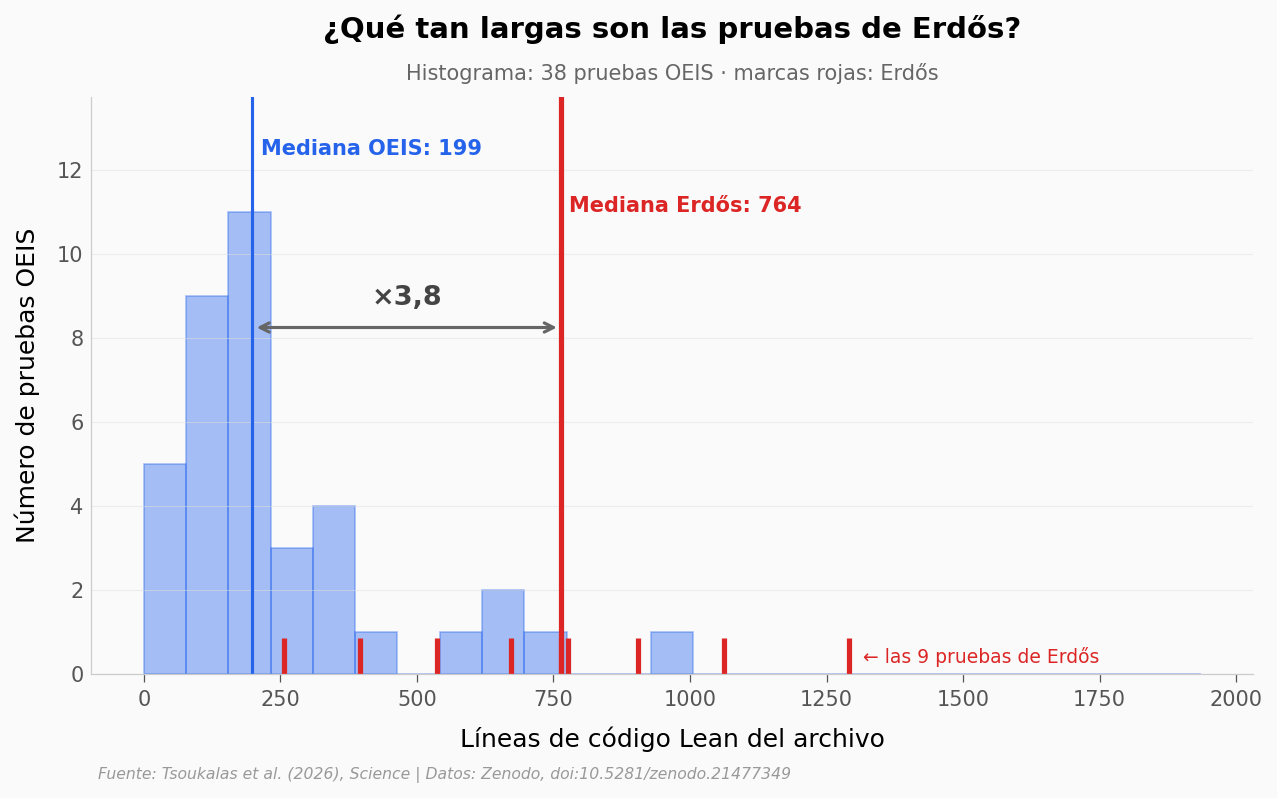

Medianas: Erdős 764 vs OEIS 199 líneas (×3,84)
Mann-Whitney U = 312, p = 0,00015, rank-biserial = 0,82 (n = 9 vs 38)
Pruebas OEIS con al menos la mediana Erdős: 1 de 38
Pruebas OEIS más cortas que la prueba Erdős más corta (257): 25 de 38
Shapiro-Wilk: OEIS p = 6,0e-05 (n = 38) | Erdős p = 9,9e-01 (n = 9)
Kruskal-Wallis entre los 4 dominios: H = 31,6, p = 6,2e-07


In [5]:
datos_hist = completas.loc[completas['dominio'] == DOMINIO_HIST, 'lineas_codigo']
datos_ref = completas.loc[completas['dominio'] == DOMINIO_REF, 'lineas_codigo']
med_hist, med_ref = datos_hist.median(), datos_ref.median()

fig, ax = plt.subplots(figsize=(10, 5))
bins = np.linspace(0, completas['lineas_codigo'].max() * 1.02, 26)
n, _, _ = ax.hist(datos_hist, bins=bins, color=COLOR_DATOS, alpha=0.4,
                  edgecolor=COLOR_DATOS, linewidth=0.8)
y_max = n.max() * 1.25
ax.set_ylim(0, y_max)
ax.plot(datos_ref, np.full(len(datos_ref), y_max * 0.03), '|', color=COLOR_ALERTA,
        markersize=18, markeredgewidth=2.5)
ax.axvline(x=med_hist, color=COLOR_DATOS, linewidth=1.5)
ax.axvline(x=med_ref, color=COLOR_ALERTA, linewidth=2.5)
ax.annotate('', xy=(med_ref, y_max * 0.6), xytext=(med_hist, y_max * 0.6),
            arrowprops=dict(arrowstyle='<->', color='#666666', lw=1.5))
ax.text((med_hist + med_ref) / 2, y_max * 0.64, f'×{es(f"{med_ref / med_hist:.1f}")}',
        ha='center', fontsize=13, fontweight='bold', color='#444444')
ax.text(med_hist + 15, y_max * 0.9, f'Mediana {NOMBRE[DOMINIO_HIST]}: {es(f"{med_hist:.0f}")}',
        fontsize=10, color=COLOR_DATOS, fontweight='bold')
ax.text(med_ref + 15, y_max * 0.8, f'Mediana {NOMBRE[DOMINIO_REF]}: {es(f"{med_ref:.0f}")}',
        fontsize=10, color=COLOR_ALERTA, fontweight='bold')
ax.text(datos_ref.max() + 25, y_max * 0.03, f'← las {len(datos_ref)} pruebas de {NOMBRE[DOMINIO_REF]}',
        fontsize=9, color=COLOR_ALERTA, ha='left', va='center')
ax.xaxis.set_major_formatter(COMA)
ax.set_xlabel('Líneas de código Lean del archivo')
ax.set_ylabel(f'Número de pruebas {NOMBRE[DOMINIO_HIST]}')
ax.set_title(f'¿Qué tan largas son las pruebas de {NOMBRE[DOMINIO_REF]}?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, f'Histograma: {len(datos_hist)} pruebas {NOMBRE[DOMINIO_HIST]} · marcas rojas: {NOMBRE[DOMINIO_REF]}',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/histograma_longitud_pruebas.png', dpi=200, bbox_inches='tight')
plt.show()

u = stats.mannwhitneyu(datos_ref, datos_hist, alternative='two-sided')
rbc = 2 * u.statistic / (len(datos_ref) * len(datos_hist)) - 1   # correlación rank-biserial
pr(f'Medianas: {NOMBRE[DOMINIO_REF]} {med_ref:.0f} vs {NOMBRE[DOMINIO_HIST]} {med_hist:.0f} líneas (×{med_ref / med_hist:.2f})')
pr(f'Mann-Whitney U = {u.statistic:.0f}, p = {u.pvalue:.5f}, rank-biserial = {rbc:.2f} (n = {len(datos_ref)} vs {len(datos_hist)})')
pr(f'Pruebas {NOMBRE[DOMINIO_HIST]} con al menos la mediana {NOMBRE[DOMINIO_REF]}: {(datos_hist >= med_ref).sum()} de {len(datos_hist)}')
pr(f'Pruebas {NOMBRE[DOMINIO_HIST]} más cortas que la prueba {NOMBRE[DOMINIO_REF]} más corta ({datos_ref.min()}): '
   f'{(datos_hist < datos_ref.min()).sum()} de {len(datos_hist)}')
pr(f'Shapiro-Wilk: {NOMBRE[DOMINIO_HIST]} p = {stats.shapiro(datos_hist).pvalue:.1e} (n = {len(datos_hist)}) | {NOMBRE[DOMINIO_REF]} p = {stats.shapiro(datos_ref).pvalue:.1e} (n = {len(datos_ref)})')
H, p_kw = stats.kruskal(*[g['lineas_codigo'] for _, g in completas.groupby('dominio')])
pr(f'Kruskal-Wallis entre los 4 dominios: H = {H:.1f}, p = {p_kw:.1e}')

Una prueba típica de Erdős es unas 3,8 veces más larga que una de la OEIS (764 contra 199 líneas de mediana). Solo 1 de las 38 pruebas OEIS alcanza la mediana de Erdős, y 25 de las 38 son más cortas que la prueba de Erdős más corta (257 líneas). La diferencia es grande (Mann-Whitney p = 0,00015; rank-biserial = 0,82), aunque con solo 9 pruebas de Erdős frente a 38. Por eso comparamos medianas y usamos tests de rangos: las longitudes de la OEIS no siguen una distribución normal (Shapiro-Wilk p < 0,001, n = 38), y con solo 9 pruebas de Erdős no se puede comprobar si las suyas la siguen.

### Lo que los datos soportan

| Afirmación | ¿Soportada? | Detalle |
|------------|-------------|---------|
| El agente resolvió 9 de los 353 problemas de Erdős que intentó (2,55 %) | ✅ | 9 archivos Lean en Zenodo y 353 entradas en la lista de intentados: coincide con el abstract. Los 353 son los formalizados en Formal Conjectures, no los más de 1.200 del catálogo |
| Probó 44 de 492 conjeturas de la OEIS (8,94 %) | ⚠️ | Es la cifra del paper. El repositorio público trae 38 pruebas OEIS (7,72 %); con los datos abiertos no podemos ubicar las 6 restantes |
| Las pruebas de Erdős son mucho más largas que las de la OEIS | ✅ | Mediana 764 contra 199 líneas (×3,8); Mann-Whitney p = 0,00015, rank-biserial = 0,82 (efecto grande); n = 9 contra 38, muestras pequeñas |
| Las pruebas más largas usan más declaraciones auxiliares (lemas y definiciones) | ✅ | ρ de Spearman = 0,85 (p < 0,001, n = 69); en parte mecánico, porque cada declaración ocupa líneas. Correlación de rangos: no la leemos como porcentaje de varianza explicada |
| Codex resolvió 7 de los 9; Claude Code, los agentes básicos con Gemini Flash y AlphaProof solo, ninguno | ⚠️ | Transcrito de la prosa del material suplementario, no medido aquí. Intentos, tiempos y prompts distintos: no es un experimento controlado |
| Un agente básico (con Gemini 3.1 Pro) replicó los éxitos en Erdős | ⚠️ | Lo dice el abstract (el modelo, Gemini 3.1 Pro, sale del material suplementario); el dato está en figuras sin números y no lo podemos verificar. Con modelos Flash, el agente básico resolvió 0 de 9 |
| El agente se está usando en combinatoria, optimización, grafos, geometría algebraica y óptica cuántica | ⚠️ | Hay 13 archivos de colaboración en el repositorio, pero los 2 de óptica cuántica son parciales (con `sorry`): en ese campo no hay ninguna prueba completa publicada. Es trabajo en curso |
| La búsqueda de pruebas formales abre la puerta al descubrimiento matemático autónomo | ⚠️ | Es la interpretación de los autores; los datos no pueden evaluarla. La búsqueda de la prueba es autónoma, pero los problemas los formalizó la comunidad y las conjeturas de la OEIS las eligió Gemini a partir de 2.649 candidatas |

> **Limitaciones:** «líneas de código» es una medida didáctica que inventamos aquí, no un estándar del campo: incluye enunciado, definiciones y lemas, y mide el tamaño del archivo, no la dificultad matemática. Las «declaraciones auxiliares» mezclan lemas y definiciones (estas son un 24 % del total). Las pruebas publicadas son las del agente completo, no las más cortas posibles. El conteo de tácticas es léxico (busca palabras en el código), así que es aproximado. El costo en dólares de cada intento no es reproducible: solo aparece en figuras.

### Ahora tú

1. **¿Las pruebas de Stacks Project se parecen más a las de Erdős o a las de la OEIS?** Pista: en la celda de configuración cambia `DOMINIO_HIST = 'StacksProject'` y vuelve a correr el histograma.
2. **¿Qué tácticas de Lean (los comandos que le dicen a Lean cómo avanzar un paso de la prueba) usa más el agente en cada tipo de problema?** Pista: la celda de abajo cuenta cuánto pesa `TACTICA` en cada dominio; prueba con `'nlinarith'` o `'simp'`.
3. **¿Cambia la tasa de éxito en Erdős si cuentas números de problema en vez de entradas?** Pista: `problemas.query("benchmark == 'Erdos'")['numero'].nunique()` y extrae el número de cada archivo de `erdos['archivo']` con una expresión regular.

In [6]:
# --- EXPERIMENTA AQUÍ ---
# ¿Cuánto pesa una táctica dentro de todas las que aparecen en cada dominio?
# Conteo léxico (busca la palabra en el código): es aproximado, no un conteo exacto de pasos.
t = tacticas[tacticas['archivo'].isin(completas['archivo'])]
total_dom = t.groupby('dominio')['usos'].sum()
uso_tactica = t[t['tactica'] == TACTICA].groupby('dominio')['usos'].sum()
print(f"'{TACTICA}' en las {len(completas)} pruebas completas: {mil(uso_tactica.sum())} apariciones de {mil(total_dom.sum())}")
for dom in total_dom.sort_values(ascending=False).index:
    pr(f'  {NOMBRE[dom]:<15} {100 * uso_tactica.get(dom, 0) / total_dom[dom]:5.1f} % de las tácticas del dominio')

print()
print('Las 5 tácticas más frecuentes por dominio:')
for dom, g in t.groupby('dominio'):
    top5 = g.groupby('tactica')['usos'].sum().sort_values(ascending=False).head(5)
    print(f'  {NOMBRE[dom]:<15} ' + ', '.join(f'{k} ({mil(v)})' for k, v in top5.items()))

'omega' en las 69 pruebas completas: 1.891 apariciones de 23.798
  OEIS             11,1 % de las tácticas del dominio
  Colaboraciones    8,9 % de las tácticas del dominio
  Erdős             8,9 % de las tácticas del dominio
  Stacks Project    0,0 % de las tácticas del dominio

Las 5 tácticas más frecuentes por dominio:
  Colaboraciones  have (1.848), rw (965), exact (760), omega (533), norm_num (419)
  Erdős           have (2.133), exact (673), rw (583), omega (502), rcases (286)
  OEIS            have (2.229), rw (965), exact (951), omega (854), norm_num (523)
  Stacks Project  have (1.475), exact (803), rw (756), use (331), apply (188)


## Créditos

- **Paper:** Tsoukalas et al. (2026). *Advancing mathematics research with AI-driven formal proof search*. Science. [DOI: 10.1126/science.aej2213](https://doi.org/10.1126/science.aej2213)
- **Datos:** las pruebas Lean de AlphaProof Nexus en Zenodo ([10.5281/zenodo.21477349](https://doi.org/10.5281/zenodo.21477349)) y la lista de conjeturas OEIS del repositorio Formal Conjectures de Google DeepMind. Los CSV de `datos/` los generamos parseando esos archivos; `comparacion_sistemas_erdos.csv` está transcrito del material suplementario (pp. S10-S11).
- **Notebook:** [Ciencia a Mordiscos · El Lab](https://github.com/Ciencia-a-Mordiscos/lab) — código bajo licencia del repositorio.

## Fuentes

**Paper**: [Advancing mathematics research with AI-driven formal proof search](https://doi.org/10.1126/science.aej2213)  
*Science, 2026-10-08 · paywall*

**Supplementary Material**: [Supplementary Materials for Advancing mathematics research with AI-driven formal proof search](https://www.science.org/doi/suppl/10.1126/science.aej2213/suppl_file/science.aej2213_sm.pdf)  
*Science, 2026-10-08*

**Datos**: [google-deepmind/alphaproof-nexus-results: v1.0.0-science-submission](https://doi.org/10.5281/zenodo.21477349)  
*Zenodo, 2026-07-21 — los 71 archivos Lean y la lista de problemas de Erdős intentados*

**Datos**: [google-deepmind/formal-conjectures — OEIS/Auto THEOREM_MAPPING.txt (rama auto_oeis)](https://github.com/google-deepmind/formal-conjectures/blob/auto_oeis/FormalConjectures/OEIS/Auto/THEOREM_MAPPING.txt)  
*GitHub, 2026-05-20 — la lista de las 492 conjeturas OEIS intentadas*

*23 afirmaciones del notebook verificadas contra estas fuentes*